# Анализ продаж супермаркета (Superstore, 2014–2017)

## О проекте

Анализ датасета продаж крупного супермаркета США. Цель — найти проблемные
категории, регионы и подкатегории, оценить динамику и сезонность,
сформулировать бизнес-рекомендации.

**Стек:** Python (pandas, matplotlib, seaborn), SQL (SQLite).

**Данные:** [Superstore Dataset](https://www.kaggle.com/datasets/vivek468/superstore-dataset-final)
— 9994 строки, 21 колонка, период 2014–2017.

**Ключевые находки:**
- Furniture — проблемная категория: маржа 2.49% (в 7 раз ниже Technology).
- Central — проблемный регион: в паре с Furniture уходит в убыток (−1.75%).
- Причина — скидки 40–51% в отдельных подкатегориях Central.
- Бизнес растёт: выручка +51%, прибыль +89% за 4 года.
- Сезонность: пики в сентябре и ноябре–декабре, провалы в январе–феврале.

**Рекомендации:**
- Ограничить скидки в Central до 15–20%.
- Пересмотреть ассортимент Tables и Machines (структурно убыточны).
- Сконцентрировать маркетинг в сентябре и ноябре.

## 1. Загрузка данных

Читаем CSV, переименовываем колонки в snake_case (нижний регистр с подчёркиваниями),
парсим даты, сохраняем в SQLite.

In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Разведка: смотрим «сырые» названия колонок, чтобы составить rename_map
df_preview = pd.read_csv('Sample - Superstore.csv', encoding='latin-1', nrows=3)
print(df_preview.columns.tolist())

['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [3]:
rename_map = {
    'Row ID': 'row_id',
    'Order ID': 'order_id',
    'Order Date': 'order_date',
    'Ship Date': 'ship_date',
    'Ship Mode': 'ship_mode',
    'Customer ID': 'customer_id',
    'Customer Name': 'customer_name',
    'Segment': 'segment',
    'Country': 'country',
    'City': 'city',
    'State': 'state',
    'Postal Code': 'postal_code',
    'Region': 'region',
    'Product ID': 'product_id',
    'Category': 'category',
    'Sub-Category': 'sub_category',
    'Product Name': 'product_name',
    'Sales': 'sales',
    'Quantity': 'quantity',
    'Discount': 'discount',
    'Profit': 'profit',
}

df = pd.read_csv(
    'Sample - Superstore.csv',
    encoding='latin-1',
    parse_dates=['Order Date', 'Ship Date']
).rename(columns=rename_map)

print(df.shape)
print(df.dtypes)
df.head()

(9994, 21)
row_id                    int64
order_id                 object
order_date       datetime64[ns]
ship_date        datetime64[ns]
ship_mode                object
customer_id              object
customer_name            object
segment                  object
country                  object
city                     object
state                    object
postal_code               int64
region                   object
product_id               object
category                 object
sub_category             object
product_name             object
sales                   float64
quantity                  int64
discount                float64
profit                  float64
dtype: object


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,...,postal_code,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


**Результат:** 9994 строки, 21 колонка. Даты корректно распознаны как `datetime64`,
числовые поля (`sales`, `discount`, `profit`) — как `float64`. Данные готовы к анализу.

In [4]:
# открываем соединение с базой
conn = sqlite3.connect('superstore.db')

In [5]:
# сохраняем датафрейм в таблицу superstore
df.to_sql('superstore', conn, if_exists='replace', index=False)

print('Готово: superstore.db создан')

Готово: superstore.db создан


In [6]:
# считаем строки в таблице
check = pd.read_sql('SELECT COUNT(*) AS n FROM superstore', conn)
print(check)

      n
0  9994


## 2. Обзор данных

Смотрим диапазон дат, уникальные категории, сегменты клиентов и регионы —
чтобы понять, с чем работаем.

In [7]:
# 1. первые 5 строк
df_first_rows = pd.read_sql('SELECT * FROM superstore LIMIT 5', conn)
print('--- Первые 5 строк ---')
print(df_first_rows)

# 2. диапазон дат заказов
df_date_range = pd.read_sql('SELECT MIN(order_date) AS min_date, MAX(order_date) AS max_date FROM superstore', conn)
print('\n--- Диапазон дат ---')
print(df_date_range)

# 3. уникальные категории
df_categories = pd.read_sql('SELECT DISTINCT category FROM superstore', conn)
print('\n--- Категории ---')
print(df_categories)

# 4. уникальные сегменты клиентов
df_segments = pd.read_sql('SELECT DISTINCT segment FROM superstore', conn)
print('\n--- Сегменты ---')
print(df_segments)

# 5. уникальные регионы
df_regions = pd.read_sql('SELECT DISTINCT region FROM superstore', conn)
print('\n--- Регионы ---')
print(df_regions)

--- Первые 5 строк ---
   row_id        order_id           order_date            ship_date  \
0       1  CA-2016-152156  2016-11-08 00:00:00  2016-11-11 00:00:00   
1       2  CA-2016-152156  2016-11-08 00:00:00  2016-11-11 00:00:00   
2       3  CA-2016-138688  2016-06-12 00:00:00  2016-06-16 00:00:00   
3       4  US-2015-108966  2015-10-11 00:00:00  2015-10-18 00:00:00   
4       5  US-2015-108966  2015-10-11 00:00:00  2015-10-18 00:00:00   

        ship_mode customer_id    customer_name    segment        country  \
0    Second Class    CG-12520      Claire Gute   Consumer  United States   
1    Second Class    CG-12520      Claire Gute   Consumer  United States   
2    Second Class    DV-13045  Darrin Van Huff  Corporate  United States   
3  Standard Class    SO-20335   Sean O'Donnell   Consumer  United States   
4  Standard Class    SO-20335   Sean O'Donnell   Consumer  United States   

              city  ... postal_code  region       product_id         category  \
0        Hen

## 3. Анализ по категориям

Смотрим, какая категория приносит больше всего выручки, прибыли и какая у неё маржа.

In [8]:
# выручка, прибыль и маржа по категориям
df_by_category = pd.read_sql('''
    SELECT
        category,
        ROUND(SUM(sales), 2) AS total_sales,
        ROUND(SUM(profit), 2) AS total_profit,
        ROUND(SUM(profit) / SUM(sales) * 100, 2) AS margin_pct,
        COUNT(DISTINCT order_id) AS num_orders
    FROM superstore
    GROUP BY category
    ORDER BY total_sales DESC
''', conn)

print(df_by_category)

          category  total_sales  total_profit  margin_pct  num_orders
0       Technology    836154.03     145454.95       17.40        1544
1        Furniture    741999.80      18451.27        2.49        1764
2  Office Supplies    719047.03     122490.80       17.04        3742


### График: маржа по категориям
Горизонтальные столбики — удобно для длинных названий категорий.
Furniture — красный (проблема), Technology и Office Supplies — нейтральные.

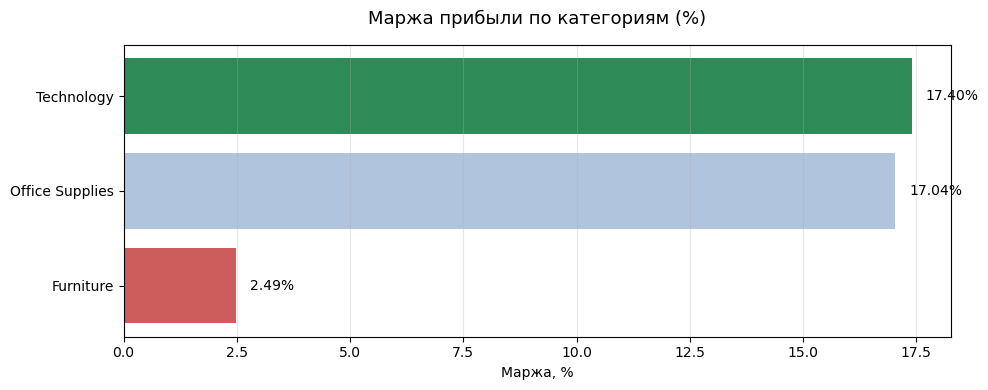

In [9]:
# график: маржа по категориям

fig, ax = plt.subplots(figsize=(10, 4))

# сортируем по марже: худший — внизу, лучший — вверху
df_sorted = df_by_category.sort_values('margin_pct')

colors = ['indianred', 'lightsteelblue', 'seagreen']

ax.barh(df_sorted['category'], df_sorted['margin_pct'], color=colors)

# подписи значений справа от столбиков
for i, value in enumerate(df_sorted['margin_pct']):
    ax.text(value + 0.3, i, f'{value:.2f}%', va='center', fontsize=10)

ax.set_title('Маржа прибыли по категориям (%)', fontsize=13, pad=15)
ax.set_xlabel('Маржа, %')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

### График: доли выручки и прибыли по категориям

Слева — доли выручки, справа — доли прибыли. Контраст:
Furniture даёт ~32% выручки, но всего ~6% прибыли.

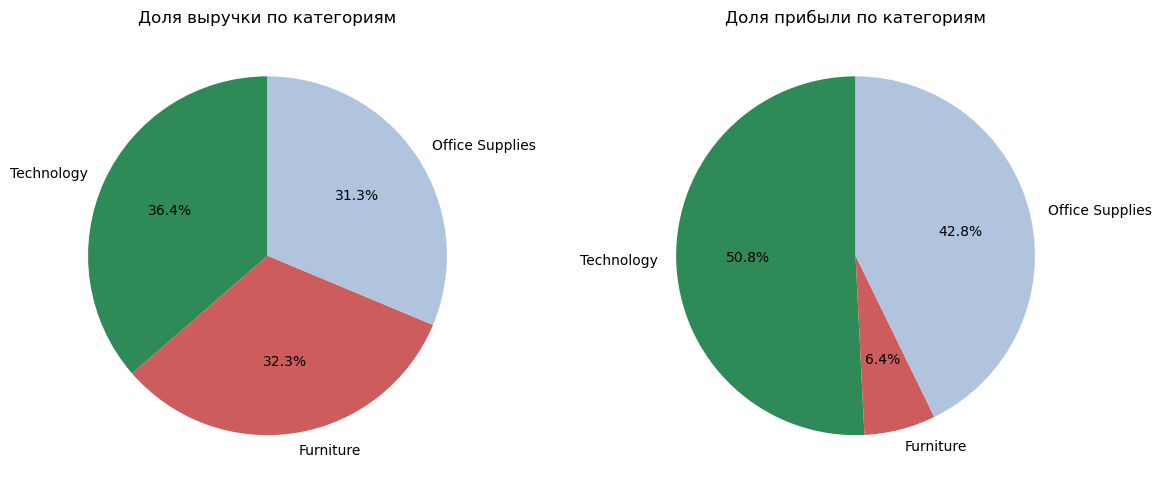

In [10]:
# круговые диаграммы: доли выручки и прибыли по категориям

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# цвета по категориям: Technology — зелёный, Furniture — красный, Office Supplies — серо-голубой
colors = ['seagreen', 'indianred', 'lightsteelblue']

# левая диаграмма — доли выручки
ax1.pie(df_by_category['total_sales'],
        labels=df_by_category['category'],
        autopct='%1.1f%%',
        colors=colors,
        startangle=90)
ax1.set_title('Доля выручки по категориям')

# правая диаграмма — доли прибыли
ax2.pie(df_by_category['total_profit'],
        labels=df_by_category['category'],
        autopct='%1.1f%%',
        colors=colors,
        startangle=90)
ax2.set_title('Доля прибыли по категориям')

plt.tight_layout()
plt.show()

### Выводы по категориям

- **Technology** — лидер по выручке (836k) и прибыли (145k). Маржа ~17%.
- **Furniture** — выручка высокая (742k), но прибыль всего 18k. Маржа ~2.5% —
  в 7 раз ниже, чем у других категорий. Требует анализа скидок и подкатегорий.
- **Office Supplies** — самая массовая (3742 заказа), но выручка самая низкая.
  Маржа здоровая (~17%).

**Результат:**
- Период: **2014-01-03 — 2017-12-30** (4 года).
- Категории: Furniture, Office Supplies, Technology.
- Сегменты: Consumer, Corporate, Home Office.
- Регионы: South, West, Central, East (без North).

## 4. Анализ по регионам

Смотрим маржу по регионам, чтобы найти проблемные и успешные.

In [11]:
# выручка и прибыль по регионам
df_by_region = pd.read_sql('''
    SELECT
        region,
        ROUND(SUM(sales), 2) AS total_sales,
        ROUND(SUM(profit), 2) AS total_profit,
        ROUND(SUM(profit) / SUM(sales) * 100, 2) AS margin_pct,
        COUNT(DISTINCT order_id) AS num_orders
    FROM superstore
    GROUP BY region
    ORDER BY total_sales DESC
''', conn)

print(df_by_region)

    region  total_sales  total_profit  margin_pct  num_orders
0     West    725457.82     108418.45       14.94        1611
1     East    678781.24      91522.78       13.48        1401
2  Central    501239.89      39706.36        7.92        1175
3    South    391721.91      46749.43       11.93         822


### Выводы по регионам

- **West** — лидер: 725k выручки, 108k прибыли, маржа 14.9%.
- **East** — близко к West: 679k / 92k, маржа 13.5%.
- **Central** — аномалия: выручка выше South, но прибыль ниже,
  маржа всего 7.9% (в 2 раза ниже West). Требует анализа структуры продаж.
- **South** — небольшой регион (822 заказа), но маржа 11.9% —
  выше Central и East.

## 5. Регион × категория

Проверяем гипотезу: почему Central слабый? Смотрим маржу по пересечению
региона и категории — так видно, где именно локализована проблема.

In [12]:
# выручка, прибыль и маржа по региону и категории
df_region_category = pd.read_sql('''
    SELECT
        region,
        category,
        ROUND(SUM(sales), 2) AS total_sales,
        ROUND(SUM(profit), 2) AS total_profit,
        ROUND(SUM(profit) / SUM(sales) * 100, 2) AS margin_pct
    FROM superstore
    GROUP BY region, category
    ORDER BY region, total_sales DESC
''', conn)

print(df_region_category)

     region         category  total_sales  total_profit  margin_pct
0   Central       Technology    170416.31      33697.43       19.77
1   Central  Office Supplies    167026.42       8879.98        5.32
2   Central        Furniture    163797.16      -2871.05       -1.75
3      East       Technology    264973.98      47462.04       17.91
4      East        Furniture    208291.20       3046.17        1.46
5      East  Office Supplies    205516.05      41014.58       19.96
6     South       Technology    148771.91      19991.83       13.44
7     South  Office Supplies    125651.31      19986.39       15.91
8     South        Furniture    117298.68       6771.21        5.77
9      West        Furniture    252612.74      11504.95        4.55
10     West       Technology    251991.83      44303.65       17.58
11     West  Office Supplies    220853.25      52609.85       23.82


### Регион × Категория: ключевая находка

| Регион | Категория | Маржа |
|---|---|---|
| Central | Furniture | **−1.75%** ← единственная убыточная комбинация |
| Central | Office Supplies | 5.32% (в 4 раза ниже West) |
| West | Office Supplies | **23.82%** ← лучшая комбинация |
| Technology (все регионы) | — | 13–20%, стабильно |

**Вывод:** проблема Central — не в категориях, а в региональной
политике продаж. Furniture убыточен именно здесь, а Office Supplies
теряет 15+ п.п. маржи по сравнению с West.

**Гипотеза:** причина — высокие скидки в Central. Проверим на подкатегориях.

### График: тепловая карта «регион × категория»

Цвет = маржа. Красный — плохо, зелёный — хорошо.
Central + Furniture (−1.75%) — единственная красная клетка.
West + Office Supplies (23.82%) — самая зелёная.

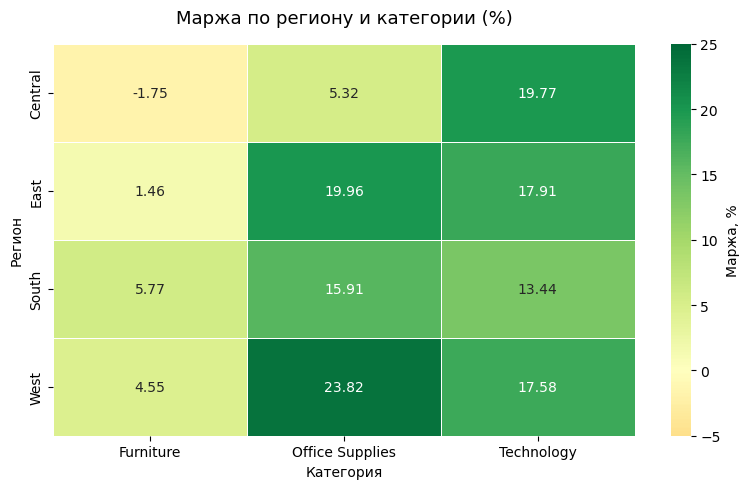

In [13]:
# тепловая карта: маржа по региону и категории

# превращаем длинный формат в широкий: регионы в строках, категории в столбцах
pivot_margin = df_region_category.pivot(
    index='region',
    columns='category',
    values='margin_pct'
)

# рисуем тепловую карту
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(pivot_margin,
            annot=True,          # подписи значений в ячейках
            fmt='.2f',           # формат: два знака после запятой
            cmap='RdYlGn',       # палитра: красный-жёлтый-зелёный
            vmin=-5,             # нижняя граница шкалы
            vmax=25,             # верхняя граница шкалы
            center=0,            # ноль — середина (жёлтый)
            linewidths=0.5,      # линии между ячейками
            cbar_kws={'label': 'Маржа, %'},  # подпись цветовой шкалы
            ax=ax)               # ось для отрисовки

ax.set_title('Маржа по региону и категории (%)', fontsize=13, pad=15)
ax.set_xlabel('Категория')
ax.set_ylabel('Регион')
plt.tight_layout()
plt.show()

## 6. Убыточные подкатегории Central

Смотрим подкатегории Central: средняя скидка, выручка, прибыль, маржа.
Сортируем по прибыли — наверху окажутся главные «виновники».

In [14]:
# скидки и прибыль по подкатегориям в Central
df_central_subs = pd.read_sql('''
    SELECT
        category,
        sub_category,
        ROUND(AVG(discount) * 100, 1) AS avg_discount_pct,
        ROUND(SUM(sales), 2) AS total_sales,
        ROUND(SUM(profit), 2) AS total_profit,
        ROUND(SUM(profit) / SUM(sales) * 100, 2) AS margin_pct
    FROM superstore
    WHERE region = 'Central'
    GROUP BY category, sub_category
    ORDER BY total_profit ASC
''', conn)

print(df_central_subs)

           category sub_category  avg_discount_pct  total_sales  total_profit  \
0         Furniture  Furnishings              40.4     15254.37      -3906.22   
1         Furniture       Tables              26.2     39154.97      -3559.65   
2   Office Supplies   Appliances              44.9     23582.03      -2638.62   
3         Furniture    Bookcases              23.3     24157.18      -1997.90   
4        Technology     Machines              32.9     26797.38      -1486.07   
5   Office Supplies      Binders              50.9     56923.28      -1043.64   
6   Office Supplies     Supplies              14.4      9467.37       -661.89   
7   Office Supplies    Fasteners              13.5       778.03        236.62   
8   Office Supplies       Labels              11.3      2451.47       1073.08   
9   Office Supplies          Art              12.3      5765.34       1195.16   
10  Office Supplies    Envelopes              12.9      4636.87       1777.53   
11  Office Supplies      Sto

### Central: 7 убыточных подкатегорий из 17

**Главный паттерн:** убыточность напрямую связана со скидкой.

| Скидка | Примеры | Маржа |
|---|---|---|
| 11–13% | Copiers, Paper, Labels | +40% и выше |
| 19% | Chairs | +7.7% |
| 23–33% | Bookcases, Tables, Machines | отрицательная |
| 40–51% | Furnishings, Appliances, Binders | глубоко отрицательная |

**Критический порог — ~20% скидки.** Выше — подкатегория уходит в минус.

**Приоритеты:**
1. Binders — скидка 51% при выручке 57k, убыток −1 044. Самый массовый
   минус в регионе.
2. Furnishings — маржа −25.6%, самая глубокая.
3. Tables — знакомая проблема (убыточна и в целом по датасету).

**Рекомендация:** ограничить максимальную скидку в Central до 15–20%
или ввести ручное согласование для более высоких значений.

## 7. Сравнение регионов по скидкам

Проверяем: те же подкатегории в других регионах продаются со скидкой меньше?
Если да — проблема именно в политике скидок Central, а не в товарах.

In [15]:
# средняя скидка и маржа по подкатегориям в разрезе регионов
df_discount_by_region = pd.read_sql('''
    SELECT
        sub_category,
        region,
        ROUND(AVG(discount) * 100, 1) AS avg_discount_pct,
        ROUND(SUM(profit) / SUM(sales) * 100, 2) AS margin_pct
    FROM superstore
    WHERE sub_category IN ('Binders', 'Furnishings', 'Tables', 'Appliances', 'Machines')
    GROUP BY sub_category, region
    ORDER BY sub_category, region
''', conn)

print(df_discount_by_region)

   sub_category   region  avg_discount_pct  margin_pct
0    Appliances  Central              44.9      -11.19
1    Appliances     East               7.3       24.54
2    Appliances    South              11.1       21.12
3    Appliances     West               3.1       27.32
4       Binders  Central              50.9       -1.83
5       Binders     East              35.3       21.06
6       Binders    South              37.6       10.53
7       Binders     West              28.2       28.76
8   Furnishings  Central              40.4      -25.61
9   Furnishings     East               7.8       20.23
10  Furnishings    South              10.7       19.89
11  Furnishings     West               3.3       25.41
12     Machines  Central              32.9       -5.55
13     Machines     East              28.4       10.48
14     Machines    South              33.3       -2.67
15     Machines     West              30.3       -1.46
16       Tables  Central              26.2       -9.09
17       T

**Главный вывод: две разные проблемы — разные решения.**

**Проблема A: скидочная политика в Central (региональная).**
- Appliances: скидка 44.9% против 3–11% в других регионах → −11% маржи.
- Furnishings: скидка 40.4% против 3–11% → −25.6% маржи.
- Binders: скидка 50.9% против 28–38% → −1.8% (порог ~40% пройден).

**Проблема B: структурно убыточные подкатегории (не региональная).**
- Tables: убыточна в Central, East, South; в West маржа всего +1.75%.
- Machines: убыточна в Central, South, West.

**Рекомендация:**
- Для проблемы A: ограничить максимальную скидку в Central 15–20%.
- Для проблемы B: пересмотреть закупочные цены или вывести из ассортимента.

## 8. Динамика по годам

Смотрим, как менялась выручка, прибыль и маржа с 2014 по 2017 год.

In [16]:
# выручка и прибыль по годам
df_by_year = pd.read_sql('''
    SELECT
        STRFTIME('%Y', order_date) AS year,
        ROUND(SUM(sales), 2) AS total_sales,
        ROUND(SUM(profit), 2) AS total_profit,
        ROUND(SUM(profit) / SUM(sales) * 100, 2) AS margin_pct,
        COUNT(DISTINCT order_id) AS num_orders
    FROM superstore
    GROUP BY year
    ORDER BY year
''', conn)

print(df_by_year)

   year  total_sales  total_profit  margin_pct  num_orders
0  2014    484247.50      49543.97       10.23         969
1  2015    470532.51      61618.60       13.10        1038
2  2016    609205.60      81795.17       13.43        1315
3  2017    733215.26      93439.27       12.74        1687


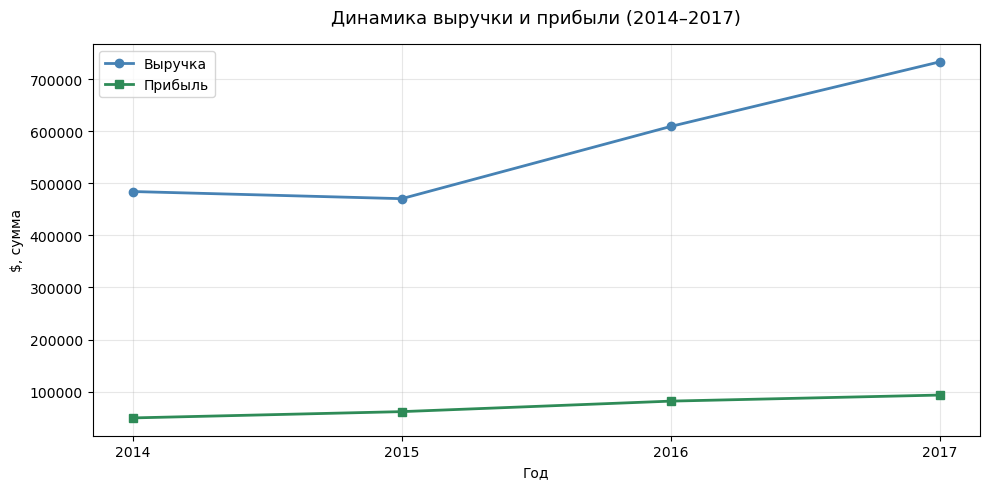

In [17]:
# график: динамика выручки и прибыли по годам

fig, ax = plt.subplots(figsize=(10, 5))

# две линии: выручка и прибыль
ax.plot(df_by_year['year'], df_by_year['total_sales'],
        marker='o', linewidth=2, color='steelblue', label='Выручка')
ax.plot(df_by_year['year'], df_by_year['total_profit'],
        marker='s', linewidth=2, color='seagreen', label='Прибыль')

ax.set_title('Динамика выручки и прибыли (2014–2017)', fontsize=13, pad=15)
ax.set_xlabel('Год')
ax.set_ylabel('$, сумма')
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

### Динамика по годам (2014–2017)

| Год | Выручка | Прибыль | Маржа | Заказы |
|---|---|---|---|---|
| 2014 | 484 248 | 49 544 | 10.23% | 969 |
| 2015 | 470 533 | 61 619 | 13.10% | 1 038 |
| 2016 | 609 206 | 81 795 | 13.43% | 1 315 |
| 2017 | 733 215 | 93 439 | 12.74% | 1 687 |

**Выводы:**
- Выручка за 4 года выросла на **+51%** (484k → 733k).
- Прибыль выросла ещё сильнее — на **+89%** (50k → 93k).
- **2015** — интересный год: выручка чуть упала, но прибыль +24%,
  маржа подскочила с 10.2% до 13.1%. Компания продавала меньше, но эффективнее.
- **2016** — пик маржи (13.43%) и сильный рост выручки (+29%).
- **2017** — рост продолжается, но маржа просела до 12.74% — сигнал
  о росте менее маржинальных продаж.

## 9. Сезонность по месяцам

Группируем все январи, все феврали и так далее — получаем средний профиль года.
Смотрим, есть ли повторяющийся паттерн.

In [18]:
# выручка по месяцам (усреднённая по годам)
df_by_month = pd.read_sql('''
    SELECT
        STRFTIME('%m', order_date) AS month_num,
        ROUND(AVG(sales), 2) AS avg_sales,
        ROUND(SUM(sales), 2) AS total_sales,
        COUNT(DISTINCT order_id) AS num_orders
    FROM superstore
    GROUP BY month_num
    ORDER BY month_num
''', conn)

print(df_by_month)

   month_num  avg_sales  total_sales  num_orders
0         01     249.15     94924.84         178
1         02     199.17     59751.25         162
2         03     294.55    205005.49         354
3         04     206.23    137762.13         343
4         05     210.92    155028.81         369
5         06     213.00    152718.68         364
6         07     207.38    147238.10         338
7         08     225.27    159044.06         341
8         09     222.45    307649.95         688
9         10     244.59    200322.98         417
10        11     239.61    352461.07         753
11        12     231.03    325293.50         702


### График: сезонность выручки

Пики — зелёным, провалы — красным, пунктир — среднее (191k).
Сразу видно, какие месяцы выше среднего, какие ниже.

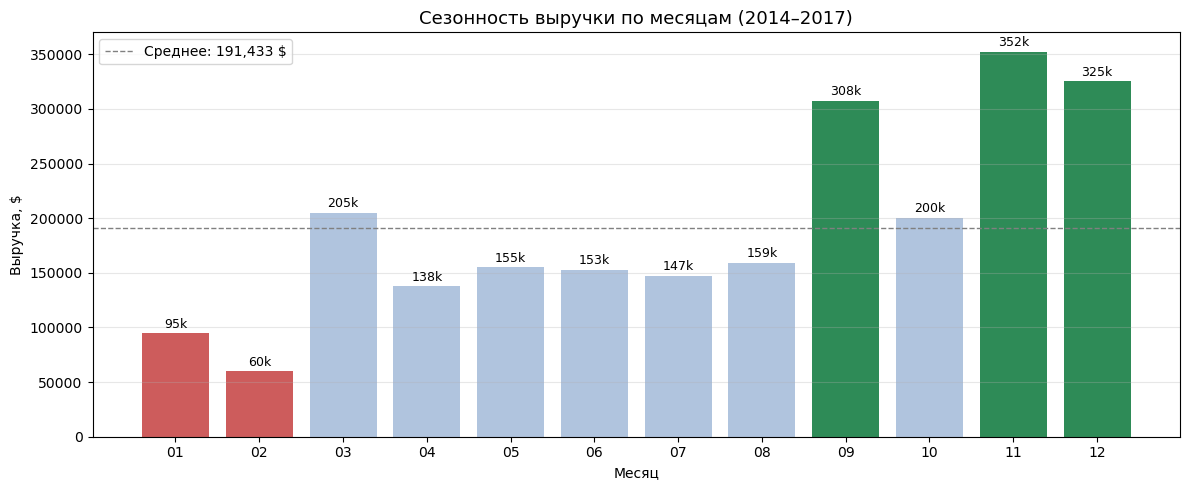

In [19]:
# график: выручка по месяцам с подсветкой пиков и среднего

# определяем цвета: пики — зелёные, провалы — красные, остальное — серое
colors = []
for month in df_by_month['month_num']:
    if month in ['09', '11', '12']:
        colors.append('seagreen')      # пики
    elif month in ['01', '02']:
        colors.append('indianred')     # провалы
    else:
        colors.append('lightsteelblue') # нейтральные

# средняя выручка по месяцам
avg_sales = df_by_month['total_sales'].mean()

# строим график
plt.figure(figsize=(12, 5))
plt.bar(df_by_month['month_num'], df_by_month['total_sales'], color=colors)

# горизонтальная линия среднего
plt.axhline(avg_sales, color='gray', linestyle='--', linewidth=1,
            label=f'Среднее: {avg_sales:,.0f} $')
plt.legend()

# подписи значений над столбиками
for i, value in enumerate(df_by_month['total_sales']):
    plt.text(i, value + 5000, f'{value/1000:.0f}k',
             ha='center', fontsize=9)

plt.title('Сезонность выручки по месяцам (2014–2017)', fontsize=13)
plt.xlabel('Месяц')
plt.ylabel('Выручка, $')
plt.xticks(df_by_month['month_num'])
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Сезонность: два пика и два провала

**Пики:**
- Ноябрь — максимум: 352k выручки, 753 заказа.
- Декабрь — второй: 325k, 702 заказа.
- Сентябрь — неожиданный выброс: 308k, 688 заказов
  (в 2 раза больше августа).

**Провалы:**
- Февраль — минимум: 60k, 162 заказа.
- Январь — 95k, 178 заказов.

**Разрыв пик/дно:** ноябрь / февраль ≈ 5.9x.

**Интерпретация:**
- Ноябрь–декабрь — праздничный сезон (чёрная пятница,
  рождество, закрытие корпоративных бюджетов).
- Сентябрь — back to school / back to office + закрытие Q3.
- Январь–февраль — затишье после праздников.

**Рекомендации:**
- Закупки под пик — заранее (июнь–июль).
- Маркетинговый бюджет — концентрировать в сентябре и ноябре.
- В феврале — снижать операционные расходы (отпуска, обучение).

## 10. Сегменты клиентов

Смотрим, кто приносит больше прибыли: Consumer, Corporate или Home Office.

In [20]:
# выручка, прибыль и маржа по сегментам
df_by_segment = pd.read_sql('''
    SELECT
        segment,
        ROUND(SUM(sales), 2) AS total_sales,
        ROUND(SUM(profit), 2) AS total_profit,
        ROUND(SUM(profit) / SUM(sales) * 100, 2) AS margin_pct,
        COUNT(DISTINCT order_id) AS num_orders,
        ROUND(AVG(sales), 2) AS avg_check
    FROM superstore
    GROUP BY segment
    ORDER BY total_sales DESC
''', conn)

print(df_by_segment)

       segment  total_sales  total_profit  margin_pct  num_orders  avg_check
0     Consumer   1161401.34     134119.21       11.55        2586     223.73
1    Corporate    706146.37      91979.13       13.03        1514     233.82
2  Home Office    429653.15      60298.68       14.03         909     240.97


### Сегменты клиентов: чем меньше, тем маржинальнее

| Segment | Выручка | Маржа | Заказы | Средний чек |
|---|---|---|---|---|
| Consumer | 1 161 401 | 11.55% | 2 586 | 223.73 |
| Corporate | 706 146 | 13.03% | 1 514 | 233.82 |
| Home Office | 429 653 | 14.03% | 909 | 240.97 |

**Выводы:**
- **Consumer** — 54% выручки, но самая низкая маржа (11.55%).
  Массовый сегмент, чувствительный к скидкам.
- **Corporate** — средний по всем показателям.
- **Home Office** — всего 19% выручки, но **лучшая маржа (14.03%)
  и самый высокий средний чек (240.97)**. Нишевый премиум-сегмент.

**Стратегия:** Consumer — для объёма, Home Office — для прибыли.
Стоит изучить, можно ли перевести часть Consumer-клиентов
в Home Office (например, через программу лояльности для фрилансеров).

## Итоговые выводы и рекомендации

### Что мы нашли

**1. Furniture — проблемная категория.**
Выручка почти как у Technology (742k против 836k), но прибыль
в 8 раз меньше. Маржа — **2.49%** против 17% у Technology и Office Supplies.
Причина — скидки 40–51% в отдельных подкатегориях.

**2. Central — проблемный регион.**
Маржа **7.92%** — в 2 раза ниже West (14.94%). При этом выручка выше,
чем у South. То есть проблема не в объёме продаж, а в их эффективности.

**3. Central + Furniture = убыток.**
Единственная убыточная комбинация из 12: **−1.75%**. В других регионах
Furniture хоть и слабая, но в плюсе. Значит, дело в региональной политике.

**4. Две разные проблемы — разные решения.**
- **Региональная проблема (скидки в Central):** Appliances, Furnishings, Binders.
  В других регионах те же подкатегории продаются со скидкой 3–11% и прибыльны.
- **Структурная проблема (подкатегории):** Tables и Machines убыточны
  в 3 из 4 регионов независимо от скидок.

**5. Бизнес растёт.**
Выручка +51%, прибыль +89% за 4 года. Прибыль растёт быстрее выручки —
компания становится эффективнее.

**6. Сильная сезонность.**
Пики — сентябрь, ноябрь, декабрь. Провалы — январь, февраль.
Разрыв пик/дно — почти 6 раз.

**7. Чем меньше сегмент — тем выше маржа.**
Consumer (54% выручки) — маржа 11.55%. Home Office (19% выручки) —
маржа 14.03% и самый высокий средний чек.

### Рекомендации

1. **Ограничить максимальную скидку в Central до 15–20%.**
   Критический порог — 20%: выше подкатегория уходит в минус.
   Приоритет — Binders (скидка 51%, убыток −1044).

2. **Пересмотреть ассортимент Tables и Machines.**
   Убыточны в 3 из 4 регионов. Варианты: поднять базовую цену,
   пересмотреть закупку или вывести из ассортимента.

3. **Сконцентрировать маркетинг в сентябре и ноябре–декабре.**
   В январе–феврале — снизить операционные расходы (отпуска, обучение).

4. **Развивать сегмент Home Office.**
   Самый маржинальный (14.03%), но самый маленький (909 заказов).
   Потенциал роста — через программу лояльности для фрилансеров
   и малого бизнеса.

5. **Провести аудит скидочной политики по всем регионам.**
   Возможно, в West и East тоже есть подкатегории со скидками 30%+,
   которые пока не ушли в минус, но близки к этому.

### Инструменты

- **Python** (pandas, matplotlib, seaborn) — обработка и визуализация.
- **SQL** (SQLite) — все агрегаты и срезы.
- **Данные:** Superstore Dataset, 9994 строки, 2014–2017.